# HBNN Workload Forecasting: Anomaly-Aware Extension

Standalone Kaggle notebook inspired by the HBNN implementation in [grass-overflow/ML_Proj](https://github.com/grass-overflow/ML_Proj).

## What this notebook does

It preserves the reference HBNN's core probabilistic architecture:

**Causal Conv1D → LSTM → Dense layers → Bayesian DenseVariational → Independent Gaussian output**

The model is trained with **negative log-likelihood (NLL)**. Stochastic Bayesian forward passes are used to estimate:
- **Aleatoric uncertainty:** average variance predicted by the Gaussian output.
- **Epistemic uncertainty:** variance across stochastic predictions of the mean.
- **Total uncertainty:** sum of aleatoric and epistemic variance.

The anomaly-aware extension compares:
1. `raw`: historical CPU/memory only.
2. `anomaly`: historical CPU/memory + causal binary anomaly flags + continuous severity scores.

The forecasting targets remain only the original CPU and memory values. This notebook does **not** replace HBNN's NLL with MSE or the LSTM's cost-sensitive loss.

## Current experiment alignment

- 11 traces: `gc11`, `gc19_a` through `gc19_h`, `ali20_c`, `ali20_g`.
- `ali18` is excluded to match the latest 11-trace LSTM run.
- Five-minute sampling, 288-step lookback (24 hours), 2-step horizon (10 minutes).
- Chronological target-index split: 80% train/validation, then 20% of that train section for validation. Approximate proportions: 64% train, 16% validation, 20% test.
- Four reference configurations: S-U, S-B, M-U, M-B.
- Both raw and anomaly-aware inputs are trained for every selected configuration.

**Important:** the reference source code contains separate hyperparameter CSVs. This notebook uses its published HBNN M-B hyperparameters as a default starting point and exposes all settings below. A full Talos hyperparameter search is not run. This is an anomaly-aware adaptation, not a claim of exact paper reproduction.

## 1. Imports, configuration and reproducibility

In [1]:
# Compatibility fix: use legacy tf_keras consistently with TensorFlow Probability layers.
import os, glob, json, time, gc, zipfile, random, warnings
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_probability as tfp
import tf_keras as keras
from tf_keras import layers
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.utils import shuffle
from sklearn.ensemble import IsolationForest
from IPython.display import display

print("TensorFlow:", tf.__version__)
print("TensorFlow Probability:", tfp.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

# Match the latest LSTM experiment trace set (ali18 deliberately excluded).
TRACES = [
    "gc11", "gc19_a", "gc19_b", "gc19_c", "gc19_d",
    "gc19_e", "gc19_f", "gc19_g", "gc19_h", "ali20_c", "ali20_g"
]
RESOURCES = ["avgcpu", "avgmem"]
WIN, HORIZON = 288, 2
TRAIN_FRAC = 0.80
VAL_FRAC = 0.20                 # fraction of pre-test training windows
SEEDS = [0, 1, 2]

# HBNN Bayesian sampling. Increase to 100-200 for stable final uncertainty estimates.
MC_SAMPLES = 100

# Runtime options. Use selected modes for an initial smoke test.
MODES = ["S-U", "S-B", "M-U", "M-B"]
INPUT_VARIANTS = ["raw", "anomaly"]
EPOCHS = 200
PATIENCE = 20
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EARLY_STOPPING = True
RESUME = True

# A conservative reference-style HBNN configuration. The reference repo's
# multibivariate/HBNN-w288-h2.csv uses 1 Conv1D layer, 16 filters, kernel 3,
# LSTM 32, MLP [32, 32], Bayesian dense width 8, Adam lr=1e-3, batch=128.
HP = dict(
    cnn_layers=1, first_conv_dim=16, first_conv_kernel=3,
    first_conv_activation="relu", second_lstm_dim=32,
    mlp_units=[32, 32], bayes_units=8, bayes_activation="relu",
    batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

ANOMALY_WINDOW = 36
ANOMALY_MIN_VOTES = 2
ANOMALY_SEED = 7
SPIKE_Q = 0.95
SERVICE_LEVELS = [0.90, 0.95, 0.99, 0.995]

OUT = Path("/kaggle/working/HBNN_11trace_anomaly_output") if Path("/kaggle/working").exists() else Path("HBNN_11trace_anomaly_output")
for sub in ["models", "history", "predictions", "checkpoints"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

print("Output directory:", OUT.resolve())

TensorFlow: 2.21.0
TensorFlow Probability: 0.25.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Output directory: /kaggle/working/HBNN_11trace_anomaly_output


## 2. Load and validate the processed traces

Upload the same Kaggle dataset used by the LSTM/LSTMD notebooks. The loader searches recursively for one CSV per trace and requires `avgcpu` and `avgmem` columns. It does not silently substitute a different trace.

In [2]:
DATA_ROOTS = [Path("/kaggle/input")] if Path("/kaggle/input").exists() else [Path(".")]

def find_trace_file(trace):
    candidates = []
    for root in DATA_ROOTS:
        candidates += list(root.rglob(f"{trace}.csv"))
        candidates += list(root.rglob(f"{trace}_flags.csv"))
    # Prefer the non-flagged preprocessed workload file.
    candidates = sorted(set(candidates), key=lambda p: ("_flags" in p.name, len(str(p))))
    for p in candidates:
        if "_flags" in p.name:
            continue
        try:
            cols = pd.read_csv(p, nrows=2).columns
            if set(RESOURCES).issubset(cols):
                return p
        except Exception:
            pass
    raise FileNotFoundError(
        f"Could not find {trace}.csv with columns {RESOURCES}. "
        "Attach the processed dataset to Kaggle Input."
    )

series = {}
data_files = {}
for trace in TRACES:
    path = find_trace_file(trace)
    df = pd.read_csv(path)
    arr = df[RESOURCES].astype("float32").to_numpy()
    if not np.isfinite(arr).all():
        raise ValueError(f"{trace} contains NaN/Inf. Clean it before training.")
    if len(arr) <= WIN + HORIZON + 10:
        raise ValueError(f"{trace} is too short for WIN={WIN}, HORIZON={HORIZON}.")
    series[trace] = arr
    data_files[trace] = str(path)
    print(f"{trace:8s} rows={len(arr):7d} | {path}")

display(pd.DataFrame({
    "trace": list(series),
    "rows": [len(series[t]) for t in series],
    "cpu_mean": [series[t][:,0].mean() for t in series],
    "mem_mean": [series[t][:,1].mean() for t in series],
}))

gc11     rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc11.csv
gc19_a   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_a.csv
gc19_b   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_b.csv
gc19_c   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_c.csv
gc19_d   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_d.csv
gc19_e   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_e.csv
gc19_f   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_f.csv
gc19_g   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_g.csv
gc19_h   rows=   8352 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_h.csv
ali20_c  rows=  13904 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali20_c.csv
ali20_g  rows=  13904 | /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali20_g.csv


,trace,rows,cpu_mean,mem_mean
0,gc11,8352,0.346187,0.455868
1,gc19_a,8352,0.632562,0.631483
2,gc19_b,8352,0.496097,0.653069
3,gc19_c,8352,0.700549,0.570482
4,gc19_d,8352,0.670209,0.501672
5,gc19_e,8352,0.560401,0.282337
6,gc19_f,8352,0.486055,0.510975
7,gc19_g,8352,0.771809,0.493169
8,gc19_h,8352,0.593755,0.467746
9,ali20_c,13904,0.361355,0.441829


## 3. Causal anomaly feature generation

Four signals are combined independently for CPU and memory:
1. **Robust Z-score:** deviation from a rolling median scaled by rolling MAD.
2. **Jump Z-score:** unusually large first differences.
3. **EWMA residual:** deviation from an exponentially weighted moving average.
4. **Isolation Forest:** unusual observations in the recent feature representation.

The binary flag is set when at least two signals vote anomalous and the robust deviation is positive. The continuous score averages normalized signal strengths. Rolling signals use past/current observations only. Isolation Forest is fitted on the training prefix only.

In [3]:
def rolling_median_mad(x, window):
    x = pd.Series(x)
    minp = max(8, window // 4)
    med = x.rolling(window, min_periods=minp).median().shift(1)
    mad = (x - med).abs().rolling(window, min_periods=minp).median().shift(1)
    return med.to_numpy(), (1.4826 * mad.to_numpy() + 1e-6)

def causal_ewma(x, alpha=0.15):
    return pd.Series(x).ewm(alpha=alpha, adjust=False).mean().shift(1).to_numpy()

def detect_anomalies(x, n_train):
    x = np.asarray(x, dtype=np.float32)
    n = len(x)
    med, robust_scale = rolling_median_mad(x, ANOMALY_WINDOW)
    rz = np.maximum((x - med) / robust_scale, 0.0)

    dx = np.diff(x, prepend=x[0])
    _, jump_scale = rolling_median_mad(dx, ANOMALY_WINDOW)
    jz = np.maximum(dx / jump_scale, 0.0)

    ewma = causal_ewma(x)
    residual = x - ewma
    _, ewma_scale = rolling_median_mad(residual, ANOMALY_WINDOW)
    ez = np.maximum(residual / ewma_scale, 0.0)

    # Isolation Forest on past-looking current value, change and residual.
    F = np.column_stack([
        np.nan_to_num(rz, nan=0.0, posinf=0.0),
        np.nan_to_num(jz, nan=0.0, posinf=0.0),
        np.nan_to_num(ez, nan=0.0, posinf=0.0),
    ])
    start = min(ANOMALY_WINDOW, max(0, n_train - 10))
    iso = IsolationForest(
        n_estimators=100, contamination="auto",
        random_state=ANOMALY_SEED, n_jobs=-1
    )
    iso.fit(F[start:n_train])
    if_score = -iso.score_samples(F)
    threshold = np.quantile(if_score[start:n_train], 0.95)
    if_vote = (if_score > threshold) & (rz > 0)

    votes = np.vstack([
        rz > 3.0,
        jz > 3.0,
        ez > 3.0,
        if_vote
    ]).astype(np.float32)
    flag = ((votes.sum(axis=0) >= ANOMALY_MIN_VOTES) & (rz > 0)).astype(np.float32)

    train_max = max(float(if_score[start:n_train].max()), float(threshold) + 1e-6)
    if_score_scaled = np.clip(
        (if_score - threshold) / (train_max - threshold + 1e-9) + 0.5, 0, 1
    )
    soft = np.vstack([
        np.clip(rz / 6.0, 0, 1),
        np.clip(jz / 6.0, 0, 1),
        np.clip(ez / 6.0, 0, 1),
        if_score_scaled * (rz > 0)
    ]).mean(axis=0).astype(np.float32)

    flag[:ANOMALY_WINDOW] = 0.0
    soft[:ANOMALY_WINDOW] = 0.0
    return flag, soft

features = {}
for t, raw in series.items():
    n_train = int(len(raw) * TRAIN_FRAC)
    cpu_flag, cpu_score = detect_anomalies(raw[:, 0], n_train)
    mem_flag, mem_score = detect_anomalies(raw[:, 1], n_train)
    # Channels: CPU, MEM, CPU_FLAG, MEM_FLAG, CPU_SCORE, MEM_SCORE
    features[t] = np.column_stack([
        raw, cpu_flag, mem_flag, cpu_score, mem_score
    ]).astype(np.float32)
    print(
        f"{t}: CPU flag={cpu_flag.mean():.3f}, MEM flag={mem_flag.mean():.3f}, "
        f"CPU score={cpu_score.mean():.3f}, MEM score={mem_score.mean():.3f}"
    )

gc11: CPU flag=0.043, MEM flag=0.042, CPU score=0.078, MEM score=0.074
gc19_a: CPU flag=0.026, MEM flag=0.022, CPU score=0.066, MEM score=0.065
gc19_b: CPU flag=0.017, MEM flag=0.020, CPU score=0.069, MEM score=0.065
gc19_c: CPU flag=0.012, MEM flag=0.017, CPU score=0.065, MEM score=0.069
gc19_d: CPU flag=0.015, MEM flag=0.032, CPU score=0.068, MEM score=0.071
gc19_e: CPU flag=0.016, MEM flag=0.017, CPU score=0.075, MEM score=0.072
gc19_f: CPU flag=0.039, MEM flag=0.039, CPU score=0.078, MEM score=0.074
gc19_g: CPU flag=0.012, MEM flag=0.050, CPU score=0.065, MEM score=0.080
gc19_h: CPU flag=0.026, MEM flag=0.040, CPU score=0.074, MEM score=0.076
ali20_c: CPU flag=0.046, MEM flag=0.043, CPU score=0.078, MEM score=0.072
ali20_g: CPU flag=0.045, MEM flag=0.045, CPU score=0.076, MEM score=0.073


## 4. Build target-indexed train/validation/test windows

Each example uses 288 observations and predicts the value two time steps after the end of the input window. Splitting is based on the target index, so test targets do not leak into training or validation.

In [4]:
def make_windows(feature_arr, target_arr, win, horizon):
    # Input ends at i+win-1; target index is i+win-1+horizon.
    last_start = len(feature_arr) - win - horizon + 1
    X = np.stack([feature_arr[i:i+win] for i in range(last_start)]).astype(np.float32)
    y_idx = np.arange(last_start) + win - 1 + horizon
    y = target_arr[y_idx].astype(np.float32)
    return X, y, y_idx

WINDOWS = {}
for t in TRACES:
    X, y, target_idx = make_windows(features[t], series[t], WIN, HORIZON)
    cutoff = int(len(series[t]) * TRAIN_FRAC)
    trainval = target_idx < cutoff
    test = ~trainval
    X_tv, y_tv = X[trainval], y[trainval]
    X_te, y_te = X[test], y[test]
    n_val = max(1, int(len(X_tv) * VAL_FRAC))
    n_fit = len(X_tv) - n_val
    if n_fit <= 0:
        raise ValueError(f"{t}: insufficient windows for train/validation split")
    WINDOWS[t] = dict(
        X_train=X_tv[:n_fit], y_train=y_tv[:n_fit],
        X_val=X_tv[n_fit:], y_val=y_tv[n_fit:],
        X_test=X_te, y_test=y_te,
        test_target_idx=target_idx[test]
    )
    print(
        f"{t:8s} train={n_fit:7d} val={n_val:6d} test={len(y_te):6d}"
    )

gc11     train=   5114 val=  1278 test=  1671
gc19_a   train=   5114 val=  1278 test=  1671
gc19_b   train=   5114 val=  1278 test=  1671
gc19_c   train=   5114 val=  1278 test=  1671
gc19_d   train=   5114 val=  1278 test=  1671
gc19_e   train=   5114 val=  1278 test=  1671
gc19_f   train=   5114 val=  1278 test=  1671
gc19_g   train=   5114 val=  1278 test=  1671
gc19_h   train=   5114 val=  1278 test=  1671
ali20_c  train=   8668 val=  2166 test=  2781
ali20_g  train=   8668 val=  2166 test=  2781


## 5. HBNN architecture and probabilistic objective

The implementation follows the repository model:
- Causal Conv1D and LSTM extract temporal features.
- Dense layers project the sequence representation.
- `DenseVariational` learns a distribution over weights (Bayesian layer).
- `IndependentNormal` outputs a Gaussian distribution for CPU/memory targets.
- Training minimizes negative log-likelihood.

The posterior is a trainable multivariate normal with a lower-triangular scale matrix. The prior is a standard multivariate normal. KL regularization is scaled by `1 / number_of_training_windows`.

In [5]:
tfpl = tfp.layers
tfd = tfp.distributions

def make_prior(kernel_size, bias_size, dtype=None):
    n = kernel_size + bias_size
    return keras.Sequential([
        tfpl.DistributionLambda(
            lambda _: tfd.MultivariateNormalDiag(
                loc=tf.zeros(n, dtype=dtype),
                scale_diag=tf.ones(n, dtype=dtype)
            )
        )
    ])

def make_posterior(kernel_size, bias_size, dtype=None):
    n = kernel_size + bias_size
    return keras.Sequential([
        tfpl.VariableLayer(tfpl.MultivariateNormalTriL.params_size(n), dtype=dtype),
        tfpl.MultivariateNormalTriL(n)
    ])

def build_hbnn(input_shape, n_targets, hp, n_train, model_name):
    inp = keras.Input(shape=input_shape, name="workload_history")
    x = inp
    for _ in range(hp["cnn_layers"]):
        x = layers.Conv1D(
            filters=hp["first_conv_dim"],
            kernel_size=hp["first_conv_kernel"],
            strides=1, padding="causal",
            activation=hp["first_conv_activation"]
        )(x)
    x = layers.LSTM(hp["second_lstm_dim"])(x)
    for units in hp["mlp_units"]:
        x = layers.Dense(units, activation="relu")(x)

    x = tfpl.DenseVariational(
        units=hp["bayes_units"],
        make_prior_fn=make_prior,
        make_posterior_fn=make_posterior,
        kl_weight=1.0 / max(int(n_train), 1),
        kl_use_exact=False,
        activation=hp["bayes_activation"],
        name="bayesian_dense"
    )(x)

    params = layers.Dense(2 * n_targets, name="gaussian_parameters")(x)
    out = tfpl.IndependentNormal(
        n_targets, convert_to_tensor_fn=tfd.Distribution.mean,
        name="predictive_gaussian"
    )(params)
    model = keras.Model(inp, out, name=model_name)

    opt = keras.optimizers.Adam(
        learning_rate=hp["learning_rate"],
        weight_decay=hp["weight_decay"]
    )
    model.compile(
        optimizer=opt,
        loss=lambda y_true, dist: -dist.log_prob(y_true),
        metrics=[
            keras.metrics.MeanSquaredError(name="mse"),
            keras.metrics.MeanAbsoluteError(name="mae")
        ]
    )
    return model

print("HBNN architecture builder ready.")

HBNN architecture builder ready.


## 6. Configuration logic

- **S-U:** one model per trace and per resource.
- **S-B:** one model per trace predicts CPU and memory jointly.
- **M-U:** one CPU model and one memory model trained across all 11 traces.
- **M-B:** one joint CPU/memory model trained across all 11 traces.

`raw` uses the two workload channels. `anomaly` uses the matching workload channel, its binary flag and its severity score. The target always remains the original resource value(s).

In [6]:
def columns_for(target_cols, variant):
    if variant == "raw":
        return list(target_cols)
    return [c for target in target_cols for c in (target, target + 2, target + 4)]

def jobs_for(mode, variant):
    jobs = []
    if mode == "S-U":
        for t in TRACES:
            for resource, col in [("cpu", 0), ("mem", 1)]:
                jobs.append(dict(
                    mode=mode, variant=variant, train_traces=[t],
                    eval_traces=[t], cols=[col], tag=f"{t}_{resource}"
                ))
    elif mode == "S-B":
        for t in TRACES:
            jobs.append(dict(
                mode=mode, variant=variant, train_traces=[t],
                eval_traces=[t], cols=[0, 1], tag=t
            ))
    elif mode == "M-U":
        for resource, col in [("cpu", 0), ("mem", 1)]:
            jobs.append(dict(
                mode=mode, variant=variant, train_traces=TRACES,
                eval_traces=TRACES, cols=[col], tag=f"all_{resource}"
            ))
    elif mode == "M-B":
        jobs.append(dict(
            mode=mode, variant=variant, train_traces=TRACES,
            eval_traces=TRACES, cols=[0, 1], tag="all"
        ))
    else:
        raise ValueError(mode)
    for j in jobs:
        j["label"] = f"{mode}-HBNN-{variant}"
    return jobs

def collect_arrays(traces, cols, variant, split):
    in_cols = columns_for(cols, variant)
    Xs, ys = [], []
    for t in traces:
        Xs.append(WINDOWS[t][f"X_{split}"][:, :, in_cols])
        ys.append(WINDOWS[t][f"y_{split}"][:, cols])
    return np.concatenate(Xs).astype(np.float32), np.concatenate(ys).astype(np.float32)

## 7. Train, estimate uncertainty and evaluate

Each trained HBNN is evaluated using repeated stochastic forward passes. The point prediction is the average sampled predictive mean. Epistemic variance is the variance of sampled means, aleatoric variance is the average sampled Gaussian variance, and total variance is their sum.

For the final evaluation, use a larger `MC_SAMPLES` (e.g. 200) if runtime permits.

In [7]:
def mc_predict(model, X, samples=MC_SAMPLES, batch_size=1024):
    means, variances = [], []
    for _ in range(samples):
        d = model(X, training=False)  # Bayesian weight sampling remains stochastic
        means.append(d.mean().numpy())
        variances.append(d.variance().numpy())
    means = np.stack(means, axis=0)
    variances = np.stack(variances, axis=0)
    mean = means.mean(axis=0)
    epistemic = means.var(axis=0)
    aleatoric = variances.mean(axis=0)
    total = epistemic + aleatoric
    return mean, aleatoric, epistemic, total

def score_predictions(y, mean, aleatoric, epistemic, total, target_cols):
    rows = []
    for k, col in enumerate(target_cols):
        res = RESOURCES[col]
        err = y[:, k] - mean[:, k]
        rows.append(dict(
            resource=res,
            MSE=float(np.mean(err**2)),
            MAE=float(np.mean(np.abs(err))),
            RMSE=float(np.sqrt(np.mean(err**2))),
            underprediction_rate=float(np.mean(mean[:, k] < y[:, k])),
            mean_aleatoric_variance=float(np.mean(aleatoric[:, k])),
            mean_epistemic_variance=float(np.mean(epistemic[:, k])),
            mean_total_variance=float(np.mean(total[:, k]))
        ))
    return rows

def service_metrics(trace, y, mean, total_var, target_cols):
    """Paper-aligned one-sided service metrics from the HBNN predictive distribution."""
    out = []
    std = np.sqrt(np.maximum(total_var, 1e-12))
    target_idx = WINDOWS[trace]["test_target_idx"]
    last_obs_idx = target_idx - HORIZON
    raw = series[trace]
    for k, col in enumerate(target_cols):
        res = RESOURCES[col]
        positive_rise = np.maximum(
            raw[1:int(len(raw)*TRAIN_FRAC), col] -
            raw[:int(len(raw)*TRAIN_FRAC)-1, col], 0.0
        )
        spike_threshold = float(np.quantile(positive_rise, SPIKE_Q))
        actual_rise = np.maximum(raw[target_idx, col] - raw[last_obs_idx, col], 0.0)
        actual_spike = actual_rise > spike_threshold
        predicted_rise = np.maximum(mean[:, k] - raw[last_obs_idx, col], 0.0)
        predicted_spike = predicted_rise > spike_threshold
        tp = int(np.sum(predicted_spike & actual_spike))
        fn = int(np.sum((~predicted_spike) & actual_spike))
        spike_recall = 100.0 * tp / (tp + fn) if (tp + fn) else np.nan

        actual = y[:, k]
        demand_total = float(np.sum(actual))
        for q in SERVICE_LEVELS:
            z = NormalDist().inv_cdf(q)
            upper = np.maximum(mean[:, k] + z * std[:, k], 0.0)
            covered = actual <= upper
            excess = np.maximum(upper - actual, 0.0)
            shortage = np.maximum(actual - upper, 0.0)
            sr = 100.0 * np.mean(covered)
            tpr_resources = 100.0 * np.sum(upper) / demand_total if demand_total > 0 else np.nan
            op = 100.0 * np.sum(excess[covered]) / demand_total if demand_total > 0 else np.nan
            up = 100.0 * np.sum(shortage[~covered]) / demand_total if demand_total > 0 else np.nan
            out.append(dict(
                resource=res, service_level=q, SR=float(sr), TPR=float(tpr_resources),
                OP=float(op), UP=float(up), spike_recall=float(spike_recall),
                TP_spike=tp, FN_spike=fn, actual_spikes=int(np.sum(actual_spike)),
                spike_threshold=spike_threshold, upper_bound_mean=float(np.mean(upper)),
                calibration_error=float(sr - q * 100.0)
            ))
    return out

def safe_tag(s):
    return s.replace("/", "_").replace(" ", "_")

## 8. Resumable experiment runner

The default full experiment runs 72 model fits before seed replication:
- S-U: 11 × 2 targets × 2 variants = 44 fits.
- S-B: 11 × 2 variants = 22 fits.
- M-U: 2 targets × 2 variants = 4 fits.
- M-B: 1 × 2 variants = 2 fits.

With 3 seeds, this becomes 216 fits. Start with `MODES = ["M-B"]` and `SEEDS = [0]` for a smoke test, then expand. Each completed fit is checkpointed to CSV/model files so interrupted sessions can resume.

In [8]:
METRIC_FILE = OUT / "HBNN_metrics.csv"
SERVICE_FILE = OUT / "HBNN_service_metrics.csv"
FIT_FILE = OUT / "HBNN_fit_log.csv"

def load_state():
    state = {"metrics": [], "service": [], "fits": [], "predictions": []}
    for key, path in [("metrics", METRIC_FILE), ("service", SERVICE_FILE), ("fits", FIT_FILE)]:
        if RESUME and path.exists():
            state[key] = pd.read_csv(path).to_dict("records")
    pred_file = OUT / "HBNN_predictions.csv"
    if RESUME and pred_file.exists():
        state["predictions"] = pd.read_csv(pred_file).to_dict("records")
    return state

state = load_state()
done = {
    (r["mode"], r["variant"], r["tag"], int(r["seed"]))
    for r in state["fits"]
}
print("Already completed fits:", len(done))

def flush_state():
    pd.DataFrame(state["metrics"]).to_csv(METRIC_FILE, index=False)
    pd.DataFrame(state["service"]).to_csv(SERVICE_FILE, index=False)
    pd.DataFrame(state["fits"]).to_csv(FIT_FILE, index=False)
    pd.DataFrame(state["predictions"]).to_csv(OUT / "HBNN_predictions.csv", index=False)

def run_fit(job, seed):
    mode, variant, tag = job["mode"], job["variant"], job["tag"]
    key = (mode, variant, tag, int(seed))
    if key in done:
        return

    keras.backend.clear_session()
    keras.utils.set_random_seed(int(seed))

    Xtr, ytr = collect_arrays(job["train_traces"], job["cols"], variant, "train")
    Xv, yv = collect_arrays(job["train_traces"], job["cols"], variant, "val")
    hp = dict(HP)
    hp["mlp_units"] = list(HP["mlp_units"])
    hp["batch_size"] = BATCH_SIZE

    model_name = safe_tag(f"HBNN_{mode}_{variant}_{tag}_seed{seed}")
    model = build_hbnn(Xtr.shape[1:], ytr.shape[1], hp, len(Xtr), model_name)

    ckpt = OUT / "checkpoints" / f"{model_name}.weights.h5"
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(ckpt), monitor="val_loss", mode="min",
            save_best_only=True, save_weights_only=True, verbose=0
        ),
        keras.callbacks.CSVLogger(str(OUT / "history" / f"{model_name}.csv"))
    ]
    if EARLY_STOPPING:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=PATIENCE,
            restore_best_weights=True, verbose=1
        ))

    t0 = time.time()
    hist = model.fit(
        Xtr, ytr, validation_data=(Xv, yv),
        epochs=EPOCHS, batch_size=hp["batch_size"],
        callbacks=callbacks, verbose=2
    )
    training_seconds = time.time() - t0
    if ckpt.exists():
        model.load_weights(str(ckpt))

    # DenseVariational uses callable prior/posterior functions that are not
    # safely serializable as a full .keras model. Save weights only;
    # rebuild the same architecture before loading these weights later.
    model_path = OUT / "models" / f"{model_name}.weights.h5"
    model.save_weights(model_path)

    for trace in job["eval_traces"]:
        in_cols = columns_for(job["cols"], variant)
        Xte = WINDOWS[trace]["X_test"][:, :, in_cols]
        yte = WINDOWS[trace]["y_test"][:, job["cols"]]
        pred_t0 = time.time()
        mean, avar, evar, tvar = mc_predict(model, Xte, MC_SAMPLES)
        inference_seconds = time.time() - pred_t0

        for metric in score_predictions(yte, mean, avar, evar, tvar, job["cols"]):
            state["metrics"].append(dict(
                mode=mode, variant=variant, tag=tag, seed=seed,
                dataset=trace, **metric
            ))
        for metric in service_metrics(trace, yte, mean, tvar, job["cols"]):
            state["service"].append(dict(
                mode=mode, variant=variant, tag=tag, seed=seed,
                dataset=trace, **metric
            ))
        for k, col in enumerate(job["cols"]):
            resource = RESOURCES[col]
            # Keep per-timepoint predictions for spike analyses and calibration plots.
            for i in range(len(yte)):
                state["predictions"].append(dict(
                    mode=mode, variant=variant, tag=tag, seed=seed,
                    dataset=trace, resource=resource, step=i,
                    actual=float(yte[i, k]), pred=float(mean[i, k]),
                    aleatoric_var=float(avar[i, k]),
                    epistemic_var=float(evar[i, k]),
                    total_var=float(tvar[i, k])
                ))

    best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
    state["fits"].append(dict(
        mode=mode, variant=variant, tag=tag, seed=seed,
        n_train=len(Xtr), n_val=len(Xv),
        epochs_run=len(hist.history["loss"]), best_epoch=best_epoch,
        best_val_nll=float(np.min(hist.history["val_loss"])),
        training_seconds=training_seconds,
        inference_seconds_per_test_trace=inference_seconds,
        mc_samples=MC_SAMPLES, model_file=model_path.name
    ))
    done.add(key)
    flush_state()
    print(f"Saved {model_name} | best epoch={best_epoch} | fit={training_seconds/60:.1f} min")

for mode in MODES:
    for variant in INPUT_VARIANTS:
        jobs = jobs_for(mode, variant)
        print(f"\n=== {mode} | {variant} | {len(jobs)} jobs ===")
        for seed in SEEDS:
            for i, job in enumerate(jobs, 1):
                if (mode, variant, job["tag"], int(seed)) in done:
                    print(f"skip {job['tag']} seed={seed}")
                    continue
                print(f"[{i}/{len(jobs)}] {job['tag']} seed={seed}")
                run_fit(job, seed)
                gc.collect()

Already completed fits: 0

=== S-U | raw | 22 jobs ===
[1/22] gc11_cpu seed=0
Epoch 1/200
40/40 - 9s - loss: 1.3159 - mse: 0.5645 - mae: 0.5841 - val_loss: 0.8908 - val_mse: 0.2396 - val_mae: 0.4022 - 9s/epoch - 215ms/step
Epoch 2/200


/usr/local/lib/python3.13/dist-packages/tf_keras/src/saving/serialization_lib.py:159: UserWarning: The object being serialized includes a `lambda`. This is unsafe. In order to reload the object, you will have to pass `safe_mode=False` to the loading function. Please avoid using `lambda` in the future, and use named Python functions instead. This is the `lambda` being serialized:             lambda _: tfd.MultivariateNormalDiag(
                loc=tf.zeros(n, dtype=dtype),
                scale_diag=tf.ones(n, dtype=dtype)
            )

  config_arr = [serialize_keras_object(x) for x in obj]


40/40 - 1s - loss: 1.5127 - mse: 0.4274 - mae: 0.5202 - val_loss: 0.7160 - val_mse: 0.1644 - val_mae: 0.3426 - 639ms/epoch - 16ms/step
Epoch 3/200
40/40 - 1s - loss: 1.1018 - mse: 0.3548 - mae: 0.4690 - val_loss: 0.5634 - val_mse: 0.1023 - val_mae: 0.2687 - 626ms/epoch - 16ms/step
Epoch 4/200
40/40 - 1s - loss: 1.1113 - mse: 0.3020 - mae: 0.4188 - val_loss: 0.8700 - val_mse: 0.2889 - val_mae: 0.4525 - 566ms/epoch - 14ms/step
Epoch 5/200
40/40 - 1s - loss: 1.1282 - mse: 0.3431 - mae: 0.4671 - val_loss: 0.8406 - val_mse: 0.2371 - val_mae: 0.4064 - 566ms/epoch - 14ms/step
Epoch 6/200
40/40 - 1s - loss: 0.9026 - mse: 0.3248 - mae: 0.3832 - val_loss: 0.9740 - val_mse: 0.2804 - val_mae: 0.4254 - 577ms/epoch - 14ms/step
Epoch 7/200
40/40 - 1s - loss: 0.7814 - mse: 0.2542 - mae: 0.3946 - val_loss: 0.8983 - val_mse: 0.3157 - val_mae: 0.4101 - 584ms/epoch - 15ms/step
Epoch 8/200
40/40 - 1s - loss: 0.9799 - mse: 0.2750 - mae: 0.4246 - val_loss: 0.9409 - val_mse: 0.2834 - val_mae: 0.4478 - 616ms/e

## 9. Aggregate raw vs anomaly-aware performance

Ratios below 1.0 indicate that the anomaly-aware model has lower error. We aggregate across datasets and seeds only after preserving per-dataset rows.

In [9]:
metrics = pd.DataFrame(state["metrics"])
if metrics.empty:
    print("No results yet. Run the training cell first.")
else:
    summary = metrics.groupby(["mode", "variant", "resource"]).agg(
        MSE=("MSE", "mean"),
        MAE=("MAE", "mean"),
        Underprediction=("underprediction_rate", "mean"),
        AleatoricVar=("mean_aleatoric_variance", "mean"),
        EpistemicVar=("mean_epistemic_variance", "mean"),
        TotalVar=("mean_total_variance", "mean"),
        traces=("dataset", "nunique"),
        runs=("seed", "nunique")
    ).reset_index()
    display(summary.round(5))
    summary.to_csv(OUT / "HBNN_raw_vs_anomaly_summary.csv", index=False)

    paired = metrics.pivot_table(
        index=["mode", "dataset", "resource", "seed"],
        columns="variant", values=["MSE", "MAE", "underprediction_rate"]
    ).dropna()
    ratio_rows = []
    for metric in ["MSE", "MAE", "underprediction_rate"]:
        if (metric, "raw") in paired.columns and (metric, "anomaly") in paired.columns:
            ratio = paired[(metric, "anomaly")] / paired[(metric, "raw")].replace(0, np.nan)
            for idx, val in ratio.dropna().items():
                ratio_rows.append(dict(
                    mode=idx[0], dataset=idx[1], resource=idx[2], seed=idx[3],
                    metric=metric, anomaly_over_raw=float(val)
                ))
    ratios = pd.DataFrame(ratio_rows)
    ratios.to_csv(OUT / "HBNN_paired_anomaly_raw_ratios.csv", index=False)
    if not ratios.empty:
        display(ratios.groupby(["mode", "metric"]).anomaly_over_raw.agg(["mean","median","count"]).round(4))

,mode,variant,resource,MSE,MAE,Underprediction,AleatoricVar,EpistemicVar,TotalVar,traces,runs
0,M-B,anomaly,avgcpu,0.00315,0.03981,0.51628,0.00288,0.00017,0.00305,11,3
1,M-B,anomaly,avgmem,0.00309,0.03713,0.48889,0.00236,0.00014,0.00251,11,3
2,M-B,raw,avgcpu,0.01977,0.09143,0.53002,0.01653,0.00014,0.01667,11,3
3,M-B,raw,avgmem,0.01791,0.08411,0.55428,0.01414,0.00009,0.01422,11,3
4,M-U,anomaly,avgcpu,0.00306,0.03921,0.49119,0.00273,0.00009,0.00282,11,3
5,M-U,anomaly,avgmem,0.00286,0.03504,0.49123,0.00243,0.00010,0.00252,11,3
6,M-U,raw,avgcpu,0.01982,0.09169,0.51769,0.01677,0.00007,0.01684,11,3
7,M-U,raw,avgmem,0.00288,0.03528,0.50530,0.00239,0.00010,0.00250,11,3
8,S-B,anomaly,avgcpu,0.02607,0.11490,0.63764,0.03675,0.00573,0.04248,11,3
9,S-B,anomaly,avgmem,0.02682,0.11854,0.61641,0.06028,0.01507,0.07535,11,3


mean  median  count
mode metric                                     
M-B  MAE                   0.7530  0.9971     66
     MSE                   0.7249  1.0070     66
     underprediction_rate  1.0707  0.9884     66
M-U  MAE                   0.8613  0.9910     66
     MSE                   0.8295  0.9889     66
     underprediction_rate  1.0408  0.9894     66
S-B  MAE                   0.9133  0.8898     66
     MSE                   1.0401  0.8667     66
     underprediction_rate  0.9658  0.9717     66
S-U  MAE                   1.0301  0.9779     66
     MSE                   1.2705  0.9583     66
     underprediction_rate  0.9633  0.9947     66

## 10. Spike-aware evaluation and paper-aligned service-level results

Spike labels are computed separately for each trace/resource from the training prefix only. For each test point, a spike is a future target whose positive rise above the last observed value exceeds the training-prefix 95th percentile of positive rises. The label is evaluation-only and is never fed to the model.

We report spike MSE/MAE and spike underprediction rate as supplementary anomaly diagnostics. The paper's service metrics are SR (one-sided upper-bound coverage), TPR (total predicted resources), OP (overprovisioned capacity on covered points), and UP (unmet demand on uncovered points). Spike-event recall is named `spike_recall` and must not be confused with the paper's TPR.


In [10]:
def spike_mask_for_test(trace, resource_col):
    raw = series[trace]
    split_idx = int(len(raw) * TRAIN_FRAC)
    positive_rise = np.maximum(raw[1:split_idx, resource_col] - raw[:split_idx-1, resource_col], 0)
    threshold = np.quantile(positive_rise, SPIKE_Q)
    idx = WINDOWS[trace]["test_target_idx"]
    last_obs_idx = idx - HORIZON
    rise = np.maximum(raw[idx, resource_col] - raw[last_obs_idx, resource_col], 0)
    return rise > threshold

pred_df = pd.DataFrame(state["predictions"])
spike_rows = []
if not pred_df.empty:
    for (mode, variant, tag, seed, trace, resource), g in pred_df.groupby(
        ["mode","variant","tag","seed","dataset","resource"]
    ):
        g = g.sort_values("step")
        col = RESOURCES.index(resource)
        mask = spike_mask_for_test(trace, col)
        if len(mask) != len(g):
            raise ValueError(f"Prediction/spike alignment mismatch for {trace}/{resource}")
        if mask.any():
            actual = g.actual.to_numpy()
            pred = g.pred.to_numpy()
            spike_rows.append(dict(
                mode=mode, variant=variant, tag=tag, seed=seed,
                dataset=trace, resource=resource,
                spike_count=int(mask.sum()),
                spike_MSE=float(np.mean((actual[mask]-pred[mask])**2)),
                spike_MAE=float(np.mean(np.abs(actual[mask]-pred[mask]))),
                spike_underprediction_rate=float(np.mean(pred[mask] < actual[mask]))
            ))
    spike_df = pd.DataFrame(spike_rows)
    display(spike_df.groupby(["mode","variant","resource"]).agg(
        spike_MSE=("spike_MSE","mean"),
        spike_MAE=("spike_MAE","mean"),
        spike_underprediction=("spike_underprediction_rate","mean"),
        traces=("dataset","nunique")
    ).round(5))
    spike_df.to_csv(OUT / "HBNN_spike_metrics.csv", index=False)

service_df = pd.DataFrame(state["service"])
if not service_df.empty:
    display(service_df.groupby(["mode","variant","resource","service_level"]).agg(
        SR=("SR","mean"), TPR=("TPR","mean")
    ).round(3))
    service_df.to_csv(OUT / "HBNN_service_summary.csv", index=False)

# Calibration error across target confidence levels (percentage points).
if not service_df.empty:
    calibration = service_df.groupby(["mode", "variant", "resource"]).apply(
        lambda g: pd.Series({
            "calibration_MAE_pp": np.mean(np.abs(g["SR"].to_numpy() - g["service_level"].to_numpy()*100)),
            "calibration_RMSE_pp": np.sqrt(np.mean((g["SR"].to_numpy() - g["service_level"].to_numpy()*100)**2))
        }), include_groups=False
    ).reset_index()
    display(calibration.round(3))
    calibration.to_csv(OUT / "HBNN_calibration_summary.csv", index=False)


spike_MSE  spike_MAE  spike_underprediction  traces
mode variant resource                                                     
M-B  anomaly avgcpu      0.01017    0.08764                0.98594      11
             avgmem      0.00888    0.07760                0.97830      11
     raw     avgcpu      0.02251    0.11789                0.89942      11
             avgmem      0.02340    0.11639                0.89983      11
M-U  anomaly avgcpu      0.00949    0.08411                0.98760      11
             avgmem      0.00921    0.07957                0.99435      11
     raw     avgcpu      0.02217    0.11654                0.89475      11
             avgmem      0.00954    0.08137                0.99242      11
S-B  anomaly avgcpu      0.03116    0.12880                0.78651      11
             avgmem      0.03400    0.13825                0.81748      11
     raw     avgcpu      0.03734    0.14542                0.75712      11
             avgmem      0.04130    0.15935                0.76613      11
S-U  anomaly avgcpu      0.06745    0.20969                0.91723      11
             avgmem      0.06434    0.19589                0.86538      11
     raw     avgcpu      0.06408    0.20717                0.89798      11
             avgmem      0.07274    0.21870                0.87508      11

SR      TPR
mode variant resource service_level                 
M-B  anomaly avgcpu   0.900          92.275  112.414
                      0.950          95.815  115.931
                      0.990          98.470  122.528
                      0.995          98.877  124.943
             avgmem   0.900          92.718  113.221
...                                     ...      ...
S-U  raw     avgcpu   0.995          99.801  287.232
             avgmem   0.900          97.986  191.220
                      0.950          99.283  224.634
                      0.990          99.859  287.315
                      0.995          99.920  310.261

[64 rows x 2 columns]

,mode,variant,resource,calibration_MAE_pp,calibration_RMSE_pp
0,M-B,anomaly,avgcpu,2.094,2.869
1,M-B,anomaly,avgmem,2.216,3.078
2,M-B,raw,avgcpu,3.679,8.237
3,M-B,raw,avgmem,3.776,6.538
4,M-U,anomaly,avgcpu,1.744,2.420
5,M-U,anomaly,avgmem,1.989,2.782
6,M-U,raw,avgcpu,3.744,7.857
7,M-U,raw,avgmem,2.087,2.848
8,S-B,anomaly,avgcpu,3.175,4.989
9,S-B,anomaly,avgmem,3.996,6.437


## 11. Diagnostic plots

The first plot compares overall MSE for raw and anomaly-aware inputs. The second shows the uncertainty decomposition. Use the per-trace tables above for workload-specific analysis.

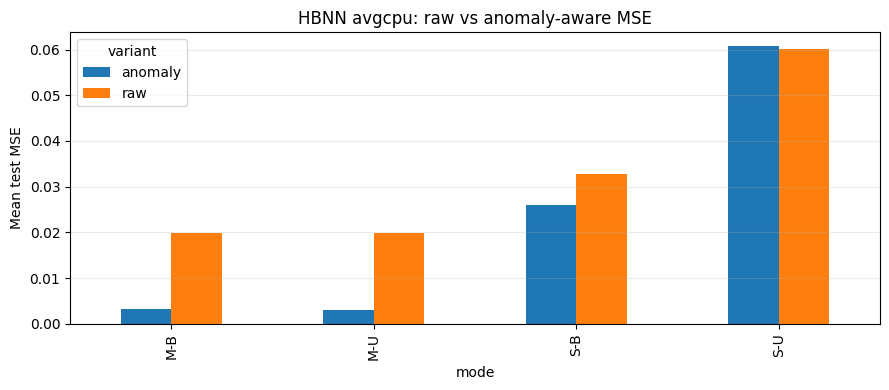

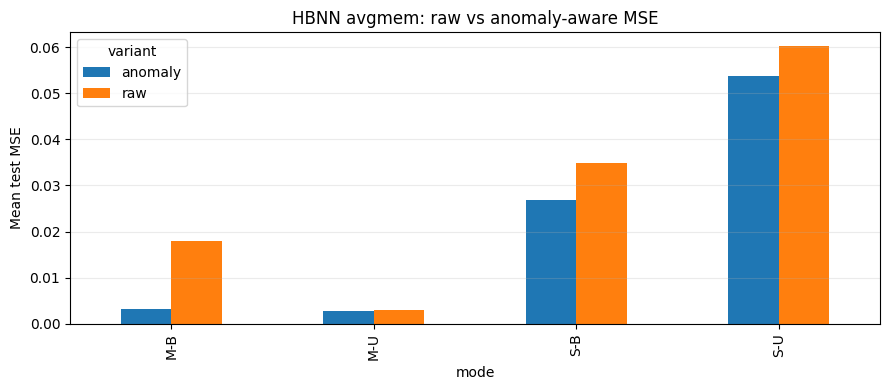

KeyError: "Columns not found: 'TotalVar', 'EpistemicVar', 'AleatoricVar'"

In [11]:
if not metrics.empty:
    plot_data = metrics.groupby(["mode","variant","resource"])["MSE"].mean().reset_index()
    for resource in RESOURCES:
        sub = plot_data[plot_data.resource == resource]
        if sub.empty: 
            continue
        pivot = sub.pivot(index="mode", columns="variant", values="MSE")
        ax = pivot.plot(kind="bar", figsize=(9,4), title=f"HBNN {resource}: raw vs anomaly-aware MSE")
        ax.set_ylabel("Mean test MSE")
        ax.grid(axis="y", alpha=.25)
        plt.tight_layout()
        plt.show()

    unc = metrics.groupby(["variant","resource"])[
        ["AleatoricVar","EpistemicVar","TotalVar"]
    ].mean()
    display(unc.round(6))

## 12. Final checks and package outputs

The output directory contains a fit log, training histories, models, point predictions with uncertainty decomposition, overall metrics, spike metrics, and service-level summaries. For a completed run, download the ZIP from Kaggle's `/kaggle/working/`.

In [ ]:
flush_state()
zip_path = OUT.parent / "HBNN_11Trace_Anomaly_Results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob("*")):
        if f.is_file() and f.suffix not in {".weights.h5"}:
            z.write(f, f.relative_to(OUT.parent))
print("Output:", OUT)
print("Completed fits:", len(state["fits"]))
print("Metrics rows:", len(state["metrics"]))
print("Prediction rows:", len(state["predictions"]))
print("ZIP:", zip_path)

In [ ]:
# Recompute paper-aligned service metrics from saved predictions.
# This corrects older resumed runs without retraining the HBNN.
pred_df = pd.DataFrame(state["predictions"])
service_rows = []
if not pred_df.empty:
    for (mode, variant, tag, seed, trace, resource), g in pred_df.groupby(
        ["mode", "variant", "tag", "seed", "dataset", "resource"]
    ):
        g = g.sort_values("step")
        actual = g["actual"].to_numpy(dtype=float)
        mean = g["pred"].to_numpy(dtype=float)
        total_var = g["total_var"].to_numpy(dtype=float)
        std = np.sqrt(np.maximum(total_var, 1e-12))
        demand_total = float(np.sum(actual))
        col = RESOURCES.index(resource)
        raw = series[trace]
        split_idx = int(len(raw) * TRAIN_FRAC)
        positive_rise = np.maximum(raw[1:split_idx, col] - raw[:split_idx-1, col], 0.0)
        spike_threshold = float(np.quantile(positive_rise, SPIKE_Q))
        idx = WINDOWS[trace]["test_target_idx"]
        last_obs_idx = idx - HORIZON
        actual_spike = np.maximum(raw[idx, col] - raw[last_obs_idx, col], 0.0) > spike_threshold
        predicted_spike = np.maximum(mean - raw[last_obs_idx, col], 0.0) > spike_threshold
        tp = int(np.sum(predicted_spike & actual_spike)); fn = int(np.sum(~predicted_spike & actual_spike))
        spike_recall = 100.0 * tp / (tp + fn) if tp + fn else np.nan
        for q in SERVICE_LEVELS:
            upper = np.maximum(mean + NormalDist().inv_cdf(q) * std, 0.0)
            covered = actual <= upper
            sr = 100.0 * np.mean(covered)
            tpr_resources = 100.0 * np.sum(upper) / demand_total if demand_total > 0 else np.nan
            op = 100.0 * np.sum(np.maximum(upper[covered]-actual[covered], 0.0)) / demand_total if demand_total > 0 else np.nan
            up = 100.0 * np.sum(np.maximum(actual[~covered]-upper[~covered], 0.0)) / demand_total if demand_total > 0 else np.nan
            service_rows.append(dict(mode=mode, variant=variant, tag=tag, seed=seed,
                dataset=trace, resource=resource, service_level=q, SR=sr, TPR=tpr_resources,
                OP=op, UP=up, spike_recall=spike_recall, calibration_error=sr-q*100.0))
service_df = pd.DataFrame(service_rows)
if not service_df.empty:
    service_df.to_csv(OUT / "HBNN_service_metrics.csv", index=False)
    service_summary = service_df.groupby(["mode", "variant", "resource", "service_level"]).agg(
        SR=("SR", "mean"), TPR=("TPR", "mean"), OP=("OP", "mean"), UP=("UP", "mean"),
        spike_recall=("spike_recall", "mean"), calibration_error=("calibration_error", "mean")
    ).reset_index()
    service_summary.to_csv(OUT / "HBNN_service_summary.csv", index=False)
    display(service_summary.round(3))
    calibration = service_summary.groupby(["mode", "variant", "resource"]).apply(
        lambda g: pd.Series({
            "calibration_MAE_pp": np.mean(np.abs(g["SR"].to_numpy()-g["service_level"].to_numpy()*100)),
            "calibration_RMSE_pp": np.sqrt(np.mean((g["SR"].to_numpy()-g["service_level"].to_numpy()*100)**2))
        }), include_groups=False
    ).reset_index()
    calibration.to_csv(OUT / "HBNN_calibration_summary.csv", index=False)
    display(calibration.round(3))
